Device: cuda
Images discovered: 325832
Classes discovered: 38
Selected images: 4978
Training images: 3982
Testing images: 996

MODEL: ResNet-50
Pretrained ImageNet weights loaded.
Epoch 1/3, Batch 100/498
Epoch 1/3, Batch 200/498
Epoch 1/3, Batch 300/498
Epoch 1/3, Batch 400/498
ResNet-50 | Epoch 1/3 | Loss: 2.2752 | Train Accuracy: 50.20%
Epoch 2/3, Batch 100/498
Epoch 2/3, Batch 200/498
Epoch 2/3, Batch 300/498
Epoch 2/3, Batch 400/498
ResNet-50 | Epoch 2/3 | Loss: 1.1784 | Train Accuracy: 77.47%
Epoch 3/3, Batch 100/498
Epoch 3/3, Batch 200/498
Epoch 3/3, Batch 300/498
Epoch 3/3, Batch 400/498
ResNet-50 | Epoch 3/3 | Loss: 0.8706 | Train Accuracy: 82.07%
Training completed for ResNet-50

ResNet-50 Test Accuracy: 82.73%
Execution time: 6.69 minutes

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.62      0.76        26
                              

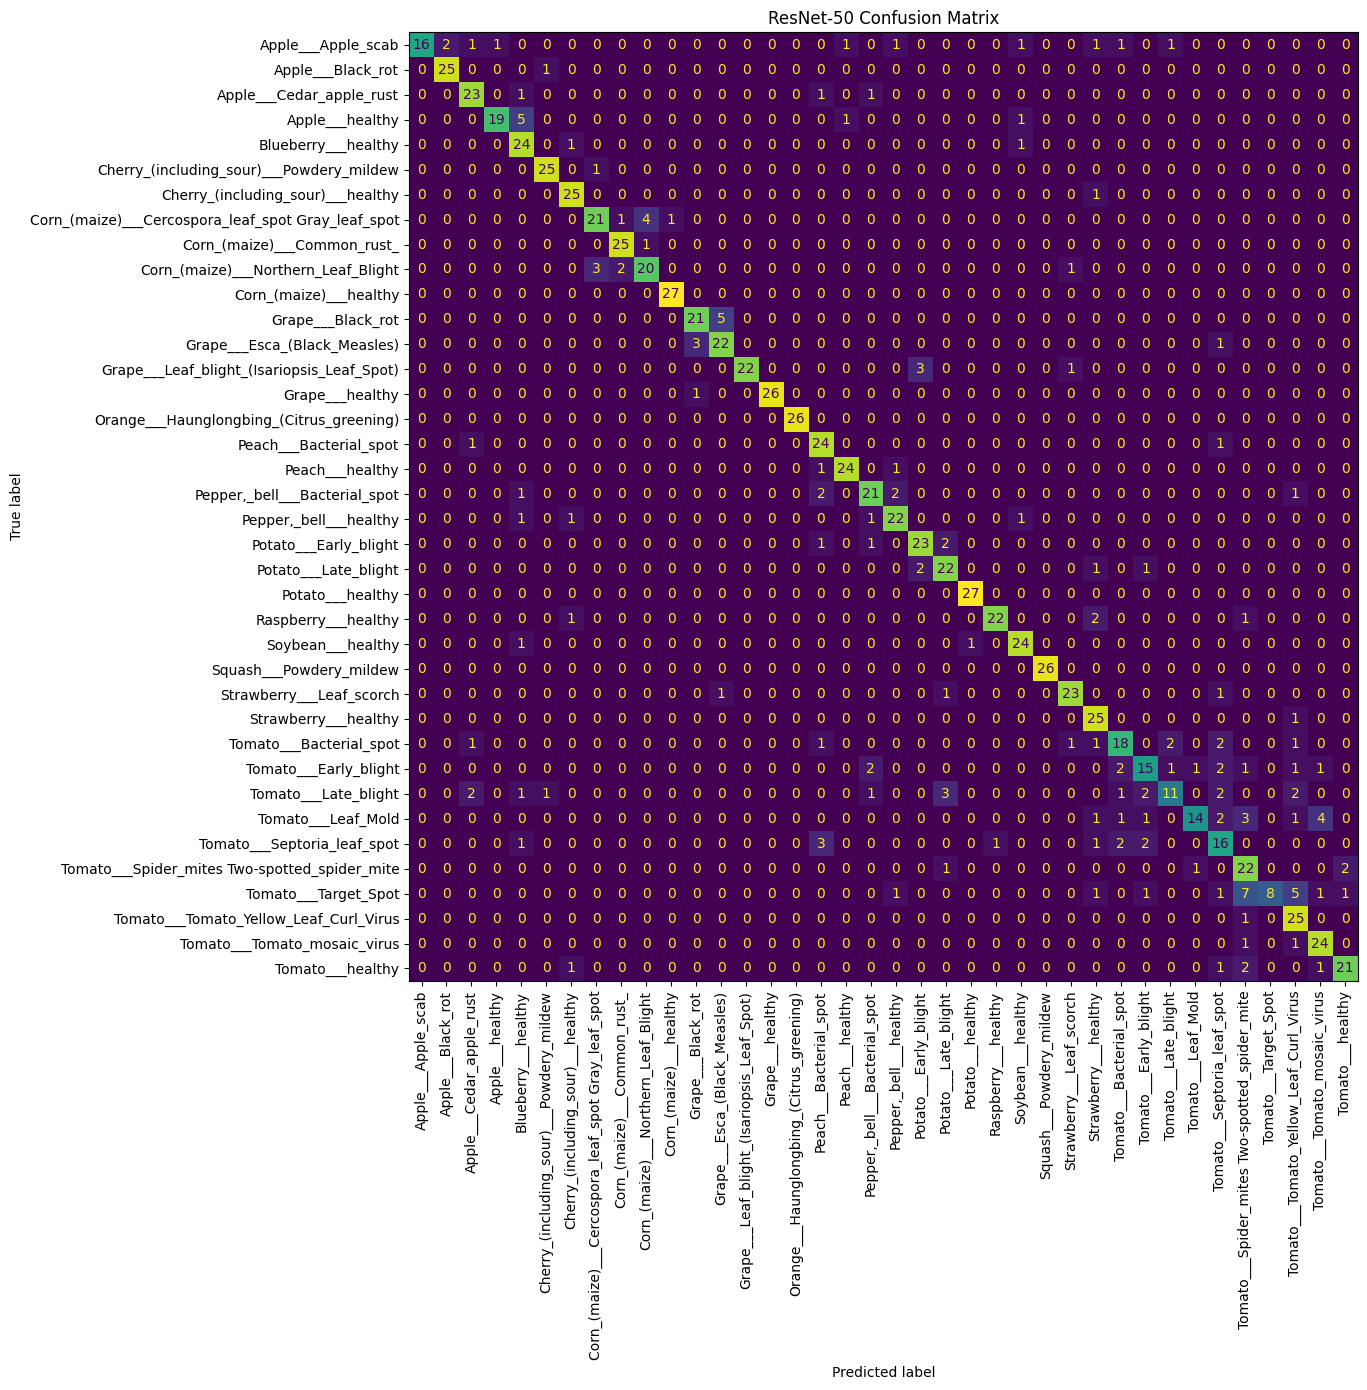

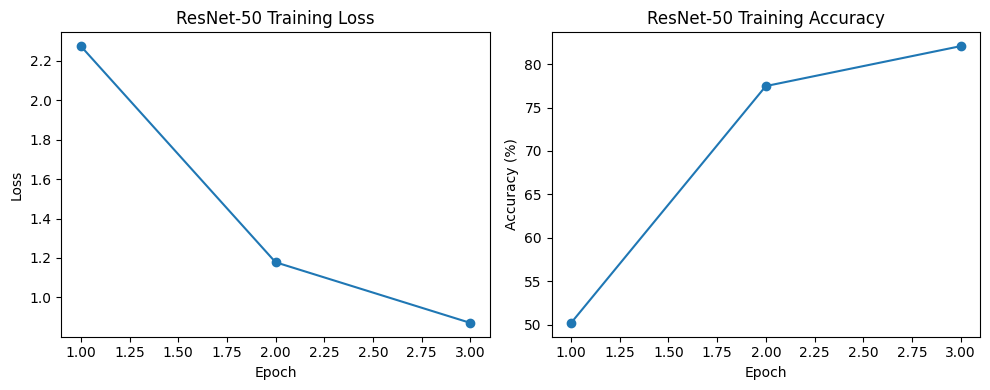

Saved model to: /kaggle/working/resnet50_plant_disease.pth

MODEL: EfficientNet-B4
Pretrained ImageNet weights loaded.
Epoch 1/3, Batch 100/498
Epoch 1/3, Batch 200/498
Epoch 1/3, Batch 300/498
Epoch 1/3, Batch 400/498
EfficientNet-B4 | Epoch 1/3 | Loss: 2.6341 | Train Accuracy: 45.83%
Epoch 2/3, Batch 100/498
Epoch 2/3, Batch 200/498
Epoch 2/3, Batch 300/498
Epoch 2/3, Batch 400/498
EfficientNet-B4 | Epoch 2/3 | Loss: 1.5935 | Train Accuracy: 68.21%
Epoch 3/3, Batch 100/498
Epoch 3/3, Batch 200/498
Epoch 3/3, Batch 300/498
Epoch 3/3, Batch 400/498
EfficientNet-B4 | Epoch 3/3 | Loss: 1.2361 | Train Accuracy: 72.98%
Training completed for EfficientNet-B4

EfficientNet-B4 Test Accuracy: 73.59%
Execution time: 0.99 minutes

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.93      0.54      0.68        26
                                 Apple___Black_rot       0.96

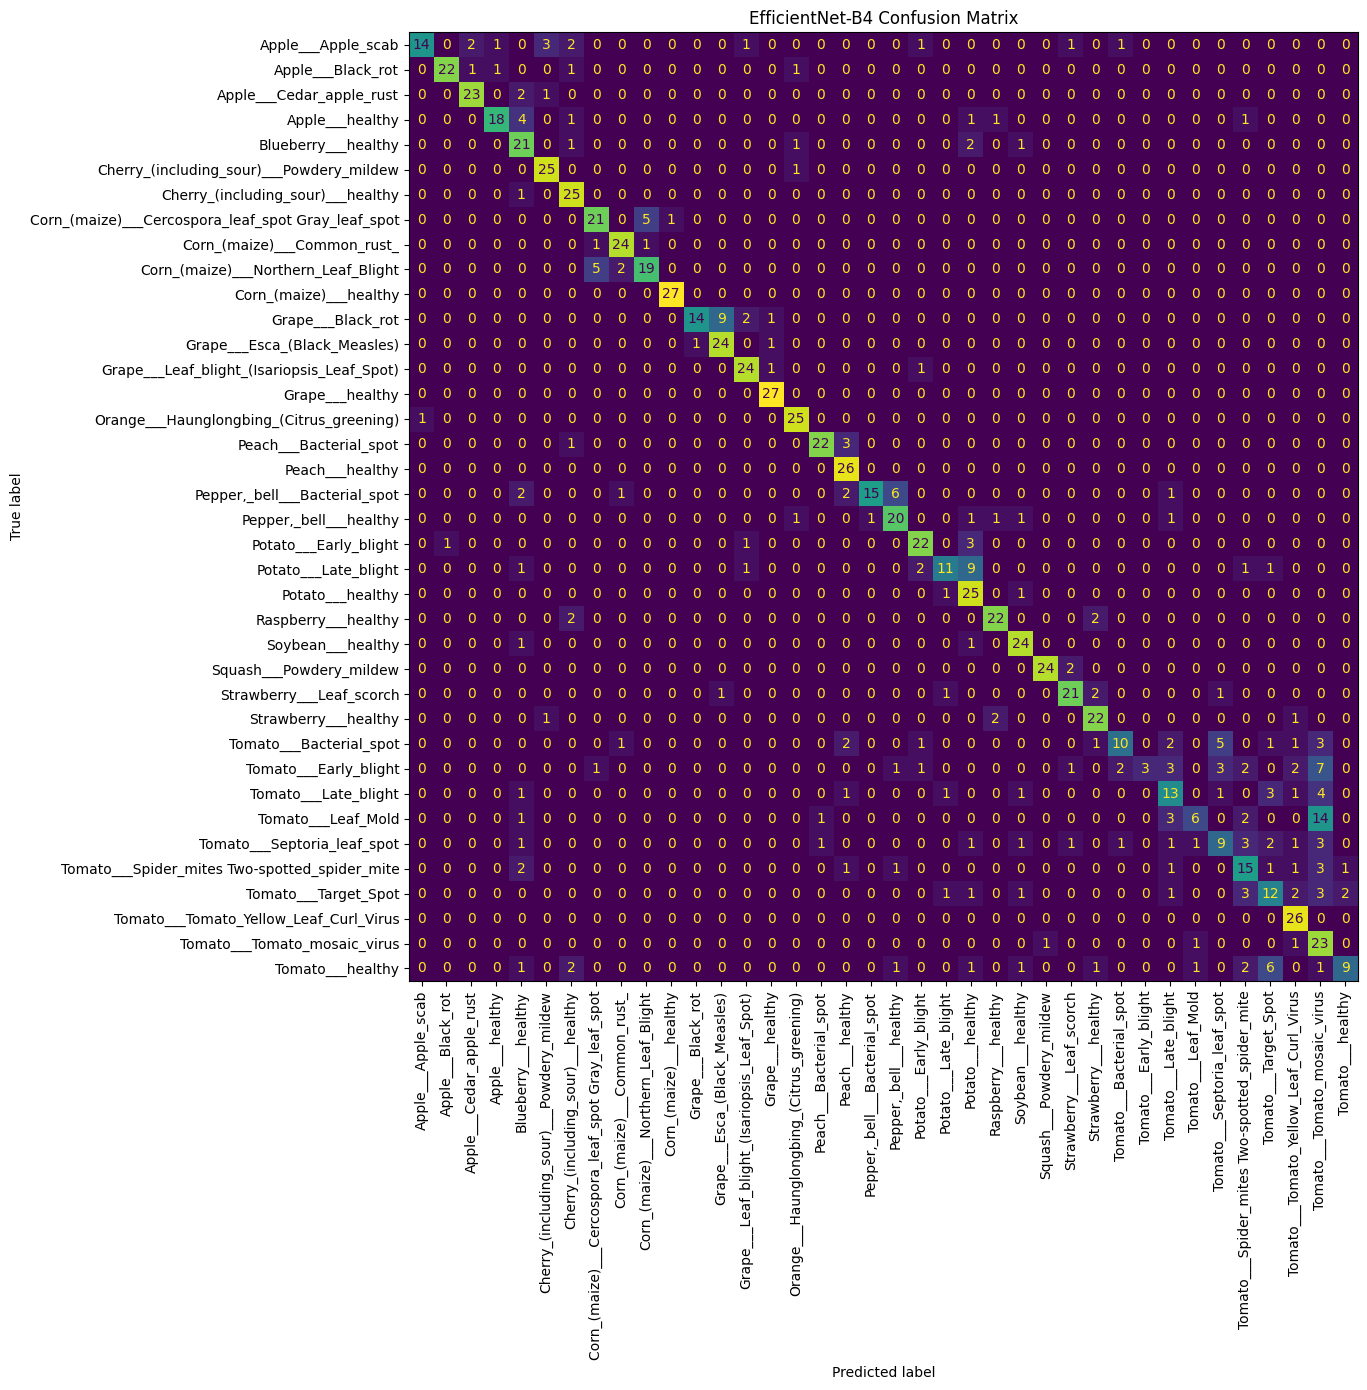

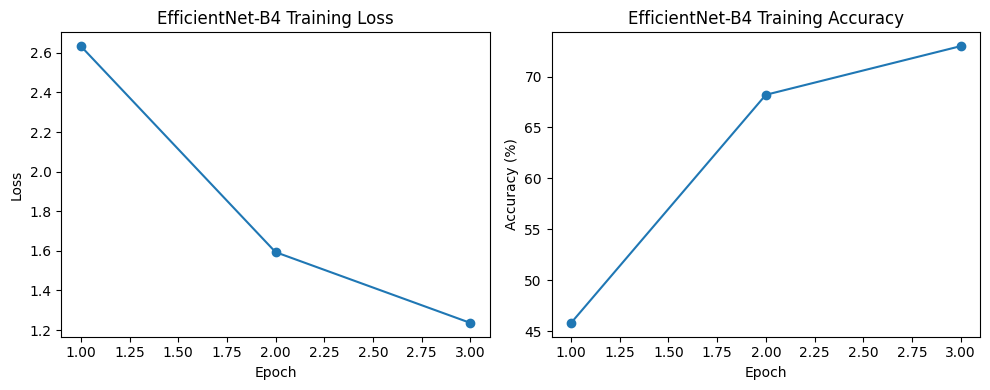

Saved model to: /kaggle/working/efficientnet_b4_plant_disease.pth

FINAL MODEL COMPARISON
          Model  Test Accuracy (%)  Execution Time (minutes)
      ResNet-50              82.73                      6.69
EfficientNet-B4              73.59                      0.99


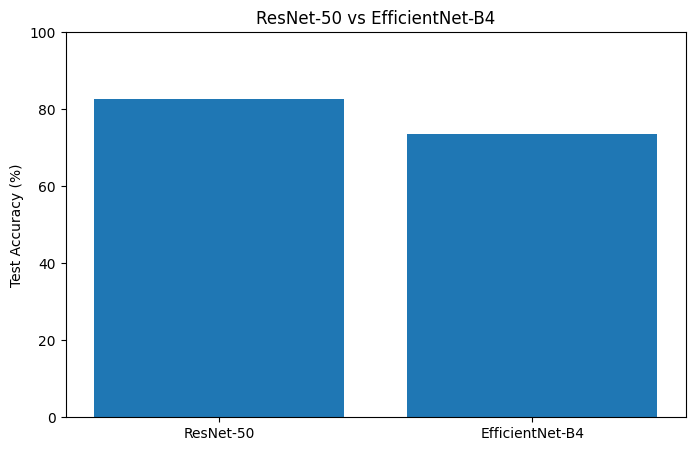

In [4]:

# PLANT DISEASE CLASSIFICATION
# RESNET-50 vs EFFICIENTNET-B4
# Run everything in ONE Kaggle cell

import os
import random
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import defaultdict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. SETTINGS
SEED = 42
MAX_IMAGES = 5000
EPOCHS = 3
BATCH_SIZE = 8
IMAGE_SIZE = 224

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cpu":
    print("WARNING: GPU is not enabled. Training both models may be slow.")

# 2. FIND DATASET IMAGES
extensions = (".jpg", ".jpeg", ".png", ".bmp")
image_list = []

for root, dirs, files in os.walk("/kaggle/input"):
    dirs.sort()
    for file in files:
        if file.lower().endswith(extensions):
            label = os.path.basename(root)

            if label.lower() not in {
                "train", "test", "val", "valid",
                "validation", "color", "grayscale",
                "segmented", "images"
            }:
                image_list.append(
                    (os.path.join(root, file), label)
                )

if not image_list:
    raise FileNotFoundError(
        "No images found. Add the PlantVillage dataset to Kaggle."
    )

counts = defaultdict(int)
for path, label in image_list:
    counts[label] += 1

image_list = [
    item for item in image_list if counts[item[1]] >= 2
]

classes = sorted(set(label for _, label in image_list))

if len(classes) < 2:
    raise ValueError("Could not identify at least two image classes.")

print("Images discovered:", len(image_list))
print("Classes discovered:", len(classes))

# 3. SELECT UP TO 5000 IMAGES, BALANCED BY CLASS
if MAX_IMAGES is not None and len(image_list) > MAX_IMAGES:
    buckets = defaultdict(list)

    for item in image_list:
        buckets[item[1]].append(item)

    selected = []
    per_class = MAX_IMAGES // len(classes)

    for label in classes:
        random.shuffle(buckets[label])
        selected.extend(buckets[label][:per_class])

    random.shuffle(selected)
    image_list = selected

classes = sorted(set(label for _, label in image_list))
class_to_idx = {name: i for i, name in enumerate(classes)}

paths = [p for p, label in image_list]
labels = [class_to_idx[label] for _, label in image_list]

print("Selected images:", len(paths))

# 4. SAME TRAIN/TEST SPLIT FOR BOTH MODELS
train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths,
    labels,
    test_size=0.2,
    random_state=SEED,
    stratify=labels
)

print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))

# 5. IMAGE TRANSFORMS
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class PlantDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        return image, self.labels[index]

train_dataset = PlantDataset(
    train_paths, train_labels, train_transform
)
test_dataset = PlantDataset(
    test_paths, test_labels, test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# 6. MODEL TRAINING AND EVALUATION FUNCTION
def train_and_test(model_name):
    start_time = time.time()
    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)

    # Load pretrained model
    try:
        if model_name == "ResNet-50":
            model = models.resnet50(
                weights=models.ResNet50_Weights.DEFAULT
            )
            model.fc = nn.Linear(
                model.fc.in_features, len(classes)
            )
        else:
            model = models.efficientnet_b4(
                weights=models.EfficientNet_B4_Weights.DEFAULT
            )
            model.classifier[1] = nn.Linear(
                model.classifier[1].in_features, len(classes)
            )

        print("Pretrained ImageNet weights loaded.")

    except Exception as e:
        print("Pretrained weights unavailable:", e)
        print("Using random initialization.")

        if model_name == "ResNet-50":
            model = models.resnet50(weights=None)
            model.fc = nn.Linear(
                model.fc.in_features, len(classes)
            )
        else:
            model = models.efficientnet_b4(weights=None)
            model.classifier[1] = nn.Linear(
                model.classifier[1].in_features, len(classes)
            )

    model = model.to(device)

    # Freeze feature extractor; train classification layer
    for param in model.parameters():
        param.requires_grad = False

    if model_name == "ResNet-50":
        for param in model.fc.parameters():
            param.requires_grad = True
        trainable_params = model.fc.parameters()
    else:
        for param in model.classifier.parameters():
            param.requires_grad = True
        trainable_params = model.classifier.parameters()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        trainable_params, lr=0.001
    )

    train_losses = []
    train_accuracies = []
    best_accuracy = -1
    best_weights = copy.deepcopy(model.state_dict())

    # Training
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for batch_no, (images, targets) in enumerate(train_loader):
            images = images.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (
                outputs.argmax(dim=1) == targets
            ).sum().item()
            total += targets.size(0)

            if (batch_no + 1) % 100 == 0:
                print(
                    f"Epoch {epoch+1}/{EPOCHS}, "
                    f"Batch {batch_no+1}/{len(train_loader)}"
                )

        epoch_loss = total_loss / total
        epoch_accuracy = correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        print(
            f"{model_name} | Epoch {epoch+1}/{EPOCHS} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Train Accuracy: {epoch_accuracy*100:.2f}%"
        )

        if epoch_accuracy > best_accuracy:
            best_accuracy = epoch_accuracy
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    print("Training completed for", model_name)

    # Testing
    model.eval()
    actual = []
    predicted = []

    with torch.no_grad():
        for images, targets in test_loader:
            images = images.to(device)
            outputs = model(images)
            predicted.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            actual.extend(targets.numpy())

    accuracy = accuracy_score(actual, predicted)
    elapsed = time.time() - start_time

    print(f"\n{model_name} Test Accuracy: {accuracy*100:.2f}%")
    print(f"Execution time: {elapsed/60:.2f} minutes")

    print("\nClassification Report:")
    print(classification_report(
        actual,
        predicted,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(
        actual, predicted,
        labels=list(range(len(classes)))
    )

    fig, ax = plt.subplots(figsize=(14, 14))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    ).plot(
        ax=ax, xticks_rotation=90,
        colorbar=False, values_format="d"
    )
    plt.title(model_name + " Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # Training graphs
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(range(1, EPOCHS+1), train_losses, marker="o")
    plt.title(model_name + " Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.subplot(1, 2, 2)
    plt.plot(
        range(1, EPOCHS+1),
        np.array(train_accuracies)*100,
        marker="o"
    )
    plt.title(model_name + " Training Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")

    plt.tight_layout()
    plt.show()

    # Save each trained model
    save_name = (
        "/kaggle/working/resnet50_plant_disease.pth"
        if model_name == "ResNet-50"
        else "/kaggle/working/efficientnet_b4_plant_disease.pth"
    )

    torch.save({
        "model_state_dict": model.state_dict(),
        "classes": classes,
        "image_size": IMAGE_SIZE
    }, save_name)

    print("Saved model to:", save_name)

    result = {
        "Model": model_name,
        "Test Accuracy (%)": round(accuracy*100, 2),
        "Execution Time (minutes)": round(elapsed/60, 2)
    }

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# 7. TRAIN BOTH MODELS
results = []

results.append(train_and_test("ResNet-50"))
results.append(train_and_test("EfficientNet-B4"))

# 8. COMPARE RESULTS
results_df = pd.DataFrame(results)

print("\n" + "=" * 55)
print("FINAL MODEL COMPARISON")
print("=" * 55)
print(results_df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(
    results_df["Model"],
    results_df["Test Accuracy (%)"]
)
plt.title("ResNet-50 vs EfficientNet-B4")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.show()
